<a href="https://colab.research.google.com/github/hjmohamedbilal/movies-dataset/blob/main/MohamedBilalHJExperiment8BTDS332.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Experiment 8: One-Way ANOVA Using the California Housing Dataset

Step 1 : Hypotheses

In [2]:
import pandas as pd
from scipy.stats import f_oneway
from sklearn.datasets import fetch_california_housing

# Load the California Housing dataset
housing = fetch_california_housing(as_frame=True)
df = housing.frame

print("First five rows:")
display(df.head())

print("Dataset shape:", df.shape)

First five rows:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


Dataset shape: (20640, 9)


Step 2: Create median-income brackets

In [3]:
# Keep the variables needed for this experiment
df = df[["MedInc", "MedHouseVal"]].dropna().copy()

# Create four income brackets using quartiles
df["IncomeBracket"] = pd.qcut(
    df["MedInc"],
    q=4,
    labels=["Low", "Lower-middle", "Upper-middle", "High"],
    duplicates="drop"
)

print("Observations per bracket:")
display(df["IncomeBracket"].value_counts().sort_index())

print("Mean house value per bracket (dataset units):")
group_means = df.groupby("IncomeBracket", observed=True)["MedHouseVal"].mean()
display(group_means)

Observations per bracket:


,count
IncomeBracket,
Low,5160
Lower-middle,5160
Upper-middle,5160
High,5160


Mean house value per bracket (dataset units):


,MedHouseVal
IncomeBracket,
Low,1.229929
Lower-middle,1.718111
Upper-middle,2.158627
High,3.167567


Step 3: State the hypotheses and perform one-way ANOVA

In [4]:
H0 = "The median house values are equal across all income brackets."
H1 = "At least one income bracket has a different mean house value."

print("Null Hypothesis (H0):", H0)
print("Alternative Hypothesis (H1):", H1)

groups = [
    group["MedHouseVal"].to_numpy()
    for _, group in df.groupby("IncomeBracket", observed=True)
]

f_statistic, p_value = f_oneway(*groups)

alpha = 0.05
print(f"\nF-statistic: {f_statistic:.6f}")
print(f"P-value: {p_value:.6e}")
print(f"Significance level (alpha): {alpha}")

if p_value < alpha:
  print("\nDecision: Reject H0.")
  print("Conclusion: Average house values differ significantly across at least two income brackets.")
else:
  print("\nDecision: Fail to reject H0.")
  print("Conclusion: There is insufficient evidence of a difference in average house values across the brackets.")

Null Hypothesis (H0): The median house values are equal across all income brackets.
Alternative Hypothesis (H1): At least one income bracket has a different mean house value.

F-statistic: 4277.066010
P-value: 0.000000e+00
Significance level (alpha): 0.05

Decision: Reject H0.
Conclusion: Average house values differ significantly across at least two income brackets.


Step 4: Optional: Visualize the group means

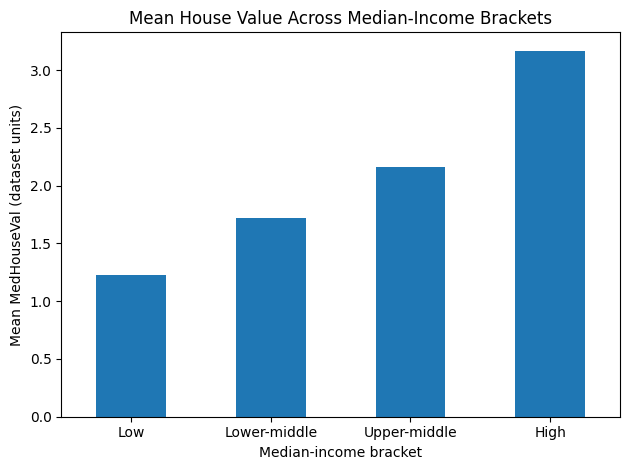

In [5]:
import matplotlib.pyplot as plt

group_means.plot(kind="bar", rot=0)
plt.xlabel("Median-income bracket")
plt.ylabel("Mean MedHouseVal (dataset units)")
plt.title("Mean House Value Across Median-Income Brackets")
plt.tight_layout()
plt.show()

Result and Conclusion

If p-value < 0.05, reject H0 and conclude that at least one income bracket has a different population mean house value.

If p-value $\ge$ 0.05, fail to reject H0; the data do not provide sufficient evidence of a difference among all bracket means.